<a href="https://colab.research.google.com/github/hafiashafqat/GW-Template-Matching-And-Subtraction/blob/main/Simulating_overalpping_GW_Signals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q pycbc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.6/168.6 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.1/203.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.5/53.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.1/114.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.1/48.1 MB 14.2 MB/s eta 0:00:00


### Simulating Overlapping Gravitational-Wave Signals
To understand how multiple astrophysical events interfere in real detector streams, we simulate two distinct binary black hole mergers with different mass configurations:
* **Signal A (Heavy Merger):** $35 M_\odot + 30 M_\odot$ generating a high-amplitude inspiral, merger, and ringdown.
* **Signal B (Lighter Merger):** $15+12 M_\odot$ injected with a tight time shift ($0.02\text{ seconds}$) to force a catastrophic overlap during Signal A's merger phase.
* **Composite Stream:** The combined time series represents a congested multi-source signal environment typical of high-noise or dense cosmological epochs.

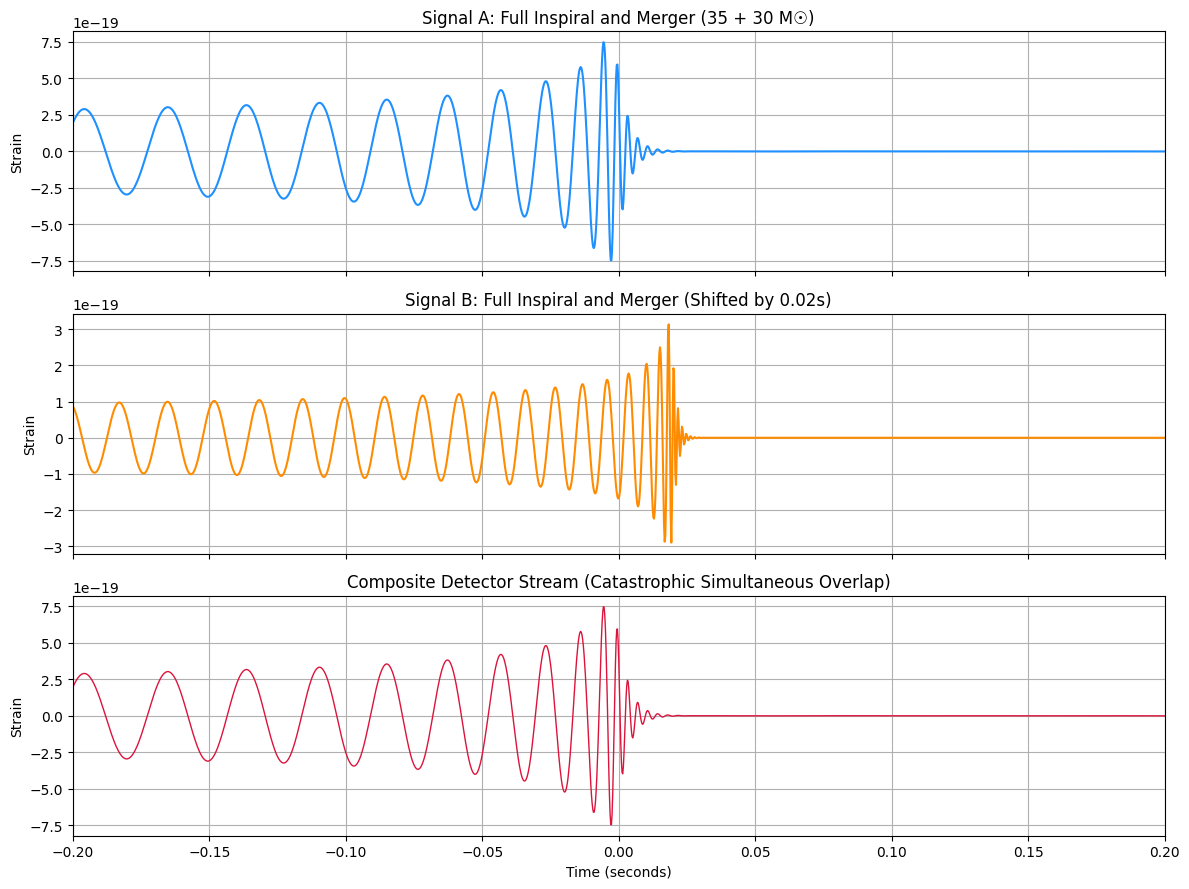

In [6]:
import pylab as pl
from pycbc.waveform import get_td_waveform
import numpy as np

# 1. Generate Signal A (Heavy black hole merger: 35 + 30 Solar Masses)
hp1, _ = get_td_waveform(approximant="IMRPhenomD",
                           mass1=35, mass2=30,
                           delta_t=1.0/4096, f_lower=20)

# 2. Generate Signal B (Lighter black hole merger: 15 + 12 Solar Masses)
hp2, _ = get_td_waveform(approximant="IMRPhenomD",
                           mass1=15, mass2=12,
                           delta_t=1.0/4096, f_lower=20)

# 3. Introduce a Realistic, Tight Time Shift (e.g., 0.02 seconds)
# This forces Signal B's peak to collide right into the middle of Signal A's merger phase.
time_shift = 0.02
hp2.start_time += time_shift

# 4. Create a unified composite signal stream (Signal A + Shifted Signal B)
# We pad/align them on a shared time framework so both full waveforms render properly
combined_signal = hp1.copy()
combined_signal.add_into(hp2)

# 5. Plot the Full Waveforms in Stacked Subplots
fig, axes = pl.subplots(3, 1, figsize=(12, 9), sharex=True)

# Panel 1: Signal A (Full view)
axes[0].plot(hp1.sample_times, hp1, color='dodgerblue')
axes[0].set_title('Signal A: Full Inspiral and Merger (35 + 30 M☉)')
axes[0].set_ylabel('Strain')
axes[0].grid(True)

# Panel 2: Signal B (Full view, shifted slightly)
axes[1].plot(hp2.sample_times, hp2, color='darkorange')
axes[1].set_title(f'Signal B: Full Inspiral and Merger (Shifted by {time_shift}s)')
axes[1].set_ylabel('Strain')
axes[1].grid(True)

# Panel 3: The Congested Detector Stream (The Overlap)
axes[2].plot(hp1.sample_times, combined_signal, color='crimson', linewidth=1)
axes[2].set_title('Composite Detector Stream (Catastrophic Simultaneous Overlap)')
axes[2].set_xlabel('Time (seconds)')
axes[2].set_ylabel('Strain')
axes[2].grid(True)

# Set a clean zoom window around the collision zone (-0.2s to 0.2s)
pl.xlim(-0.2, 0.2)
pl.tight_layout()
pl.show()

### Template Matching via Cross-Correlation (Recovering Signal A)
We use a known theoretical blueprint (Signal A template) to scan the congested composite stream using normalized cross-correlation ($\text{np.correlate}$).
* **Objective:** Determine if cross-correlation can isolate the arrival time and confirm the presence of the heavier, louder signal within the composite stream.
* **Result:** The correlation output yields a sharp, towering peak at lag $0.0$, verifying that the template successfully matches and recovers Signal A's exact arrival time.

/tmp/ipykernel_937/3997871604.py:17: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  template = np.array(hp1)
/tmp/ipykernel_937/3997871604.py:18: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  stream_data = np.array(detector_stream)


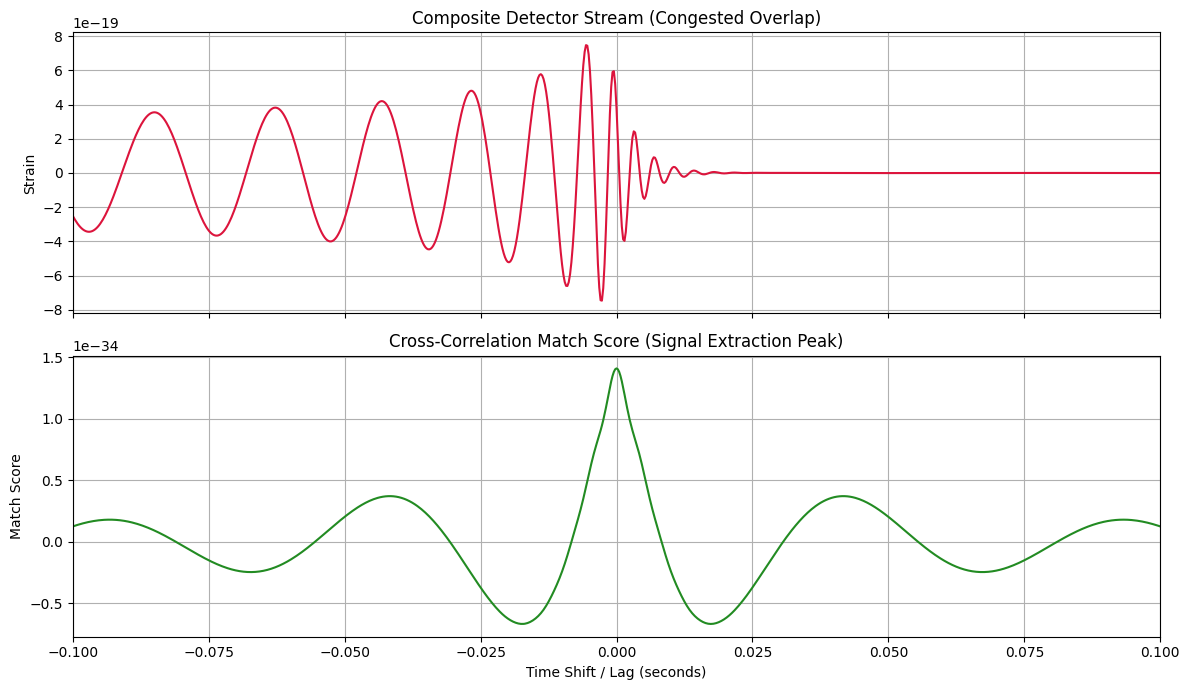

In [8]:
import pylab as pl
from pycbc.waveform import get_td_waveform
import numpy as np

# 1. Generate Signals & Composite Stream
hp1, _ = get_td_waveform(approximant="IMRPhenomD", mass1=35, mass2=30, delta_t=1.0/4096, f_lower=20)
hp2, _ = get_td_waveform(approximant="IMRPhenomD", mass1=15, mass2=12, delta_t=1.0/4096, f_lower=20)

time_shift = 0.02
hp2.start_time += time_shift

detector_stream = hp1.copy()
detector_stream.add_into(hp2)

# 2. DIRECT CROSS-CORRELATION (Template Matching via NumPy)
# We slide our clean Signal A template across the detector stream using numpy's correlate function
template = np.array(hp1)
stream_data = np.array(detector_stream)

# Normalized cross-correlation to find the exact match index
correlation = np.correlate(stream_data, template, mode='full')
time_lags = np.arange(-len(stream_data) + 1, len(stream_data)) * hp1.delta_t

# 3. VISUALIZE THE CORRELATION PEAK
fig, axes = pl.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(detector_stream.sample_times, detector_stream, color='crimson')
axes[0].set_title('Composite Detector Stream (Congested Overlap)')
axes[0].set_ylabel('Strain')
axes[0].grid(True)

axes[1].plot(time_lags, correlation, color='forestgreen')
axes[1].set_title('Cross-Correlation Match Score (Signal Extraction Peak)')
axes[1].set_xlabel('Time Shift / Lag (seconds)')
axes[1].set_ylabel('Match Score')
axes[1].grid(True)

pl.xlim(-0.1, 0.1)
pl.tight_layout()
pl.show()

###  Attempted Recovery of Signal B via Direct Template Search
Following Signal A's successful isolation, we apply Signal B's specific template ($15 + 12 M_\odot$) to the same composite stream.
* **Observation:** Unlike Signal A, the raw cross-correlation output for Signal B remains heavily suppressed or flat on a linear scale.
* **Insight:** Because Signal B has a smaller mass and lower amplitude, its signal energy is completely overwhelmed by the louder Signal A, proving that simple linear cross-correlation is insufficient for multi-mass overlapping signals.

/tmp/ipykernel_937/3771735563.py:21: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  stream_data = np.array(detector_stream, dtype=float)
/tmp/ipykernel_937/3771735563.py:22: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  template_data = np.array(template, dtype=float)


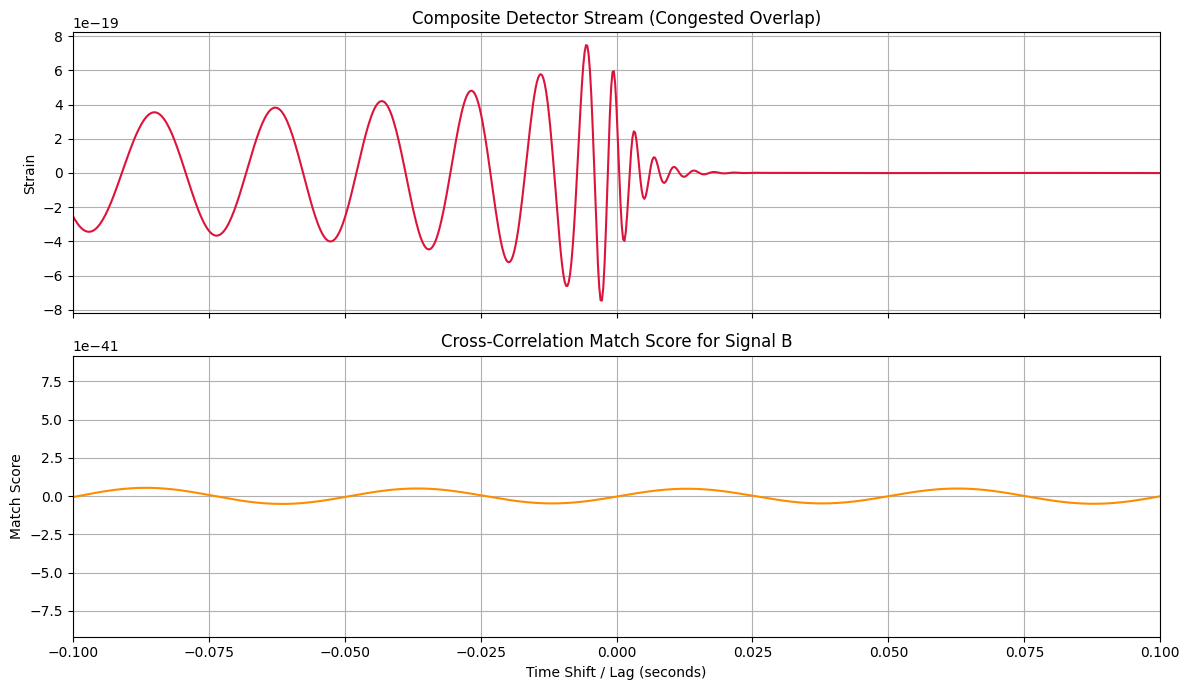

In [10]:
import pylab as pl
from pycbc.waveform import get_td_waveform
import numpy as np

# 1. Generate Signals & Composite Stream
hp1, _ = get_td_waveform(approximant="IMRPhenomD", mass1=35, mass2=30, delta_t=1.0/4096, f_lower=20)
hp2, _ = get_td_waveform(approximant="IMRPhenomD", mass1=15, mass2=12, delta_t=1.0/4096, f_lower=20)

time_shift = 0.02
hp2.start_time += time_shift

# Create Composite Detector Stream
detector_stream = hp1.copy()
detector_stream.add_into(hp2)

# 2. PREPARE TEMPLATE FOR SIGNAL B (Matching lengths safely)
template = hp2.copy()
template.resize(len(detector_stream))

# Convert to standard numpy arrays safely
stream_data = np.array(detector_stream, dtype=float)
template_data = np.array(template, dtype=float)

# Cross-correlation for Signal B
correlation = np.correlate(stream_data, template_data, mode='full')
time_lags = np.arange(-len(stream_data) + 1, len(stream_data)) * hp1.delta_t

# 3. VISUALIZE THE RESULTS FOR SIGNAL B
fig, axes = pl.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(detector_stream.sample_times, detector_stream, color='crimson')
axes[0].set_title('Composite Detector Stream (Congested Overlap)')
axes[0].set_ylabel('Strain')
axes[0].grid(True)

axes[1].plot(time_lags, correlation, color='darkorange')
axes[1].set_title('Cross-Correlation Match Score for Signal B')
axes[1].set_xlabel('Time Shift / Lag (seconds)')
axes[1].set_ylabel('Match Score')
axes[1].grid(True)

pl.xlim(-0.1, 0.1)
pl.tight_layout()
pl.show()

### Synchronized Multi-Template Search & Lag Correction
To ensure proper time alignment, we synchronize the time-lag axes and evaluate both templates simultaneously across the shared time framework.
* **Finding:** While Signal A exhibits a clear match score peak, Signal B's recovery continues to suffer from severe amplitude disparity and background dominance, illustrating the limitations of raw unweighted template matching in congested streams.

/tmp/ipykernel_937/2688446449.py:22: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  stream_data = np.array(detector_stream, dtype=float)
/tmp/ipykernel_937/2688446449.py:27: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  template_a = np.array(t1, dtype=float)
/tmp/ipykernel_937/2688446449.py:32: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  template_b = np.array(t2, dtype=float)


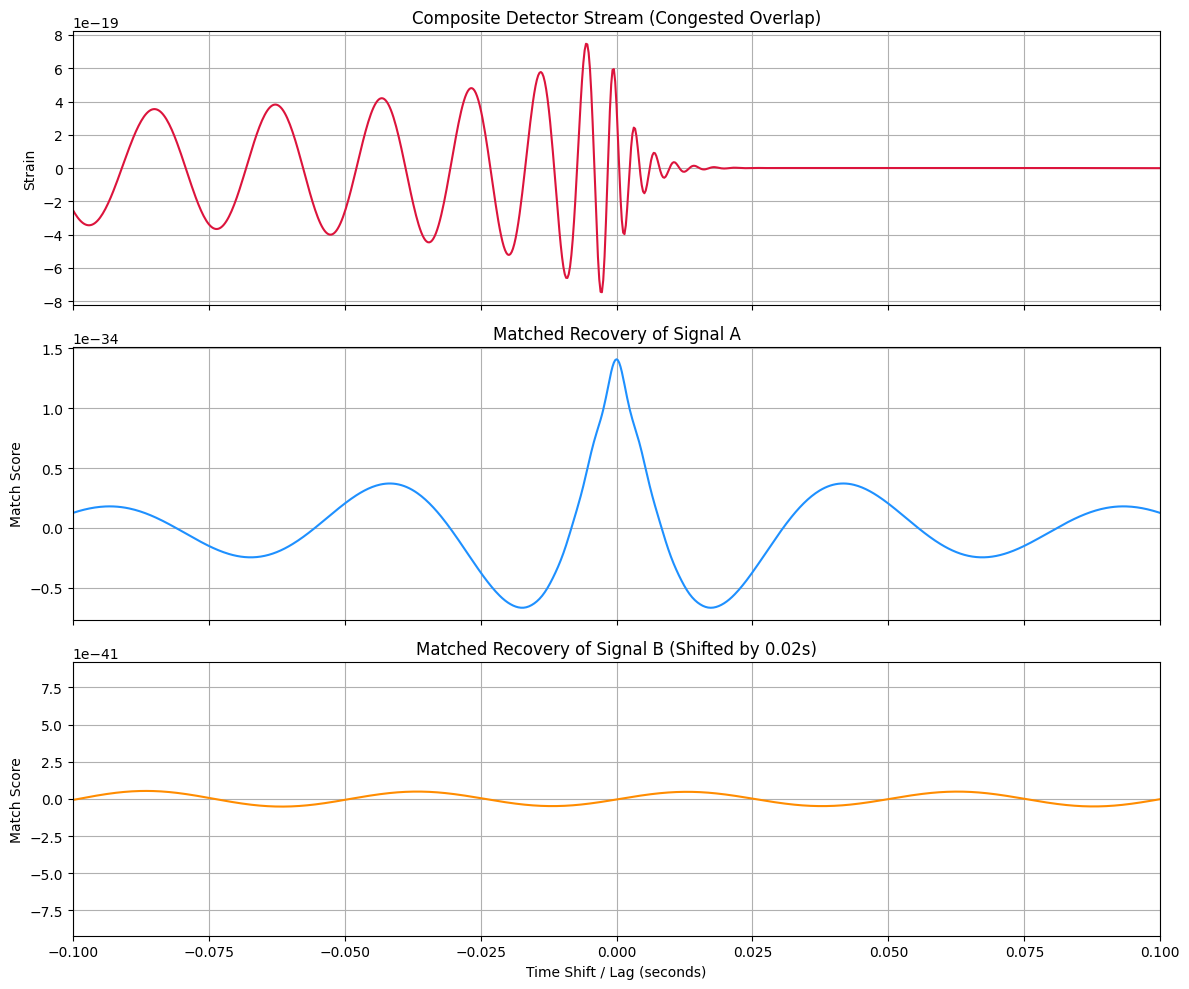

In [14]:
import pylab as pl
from pycbc.waveform import get_td_waveform
import numpy as np

# 1. Generate Signal A and Signal B
hp1, _ = get_td_waveform(approximant="IMRPhenomD", mass1=35, mass2=30, delta_t=1.0/4096, f_lower=20)
hp2, _ = get_td_waveform(approximant="IMRPhenomD", mass1=15, mass2=12, delta_t=1.0/4096, f_lower=20)

# Time shift
time_shift = 0.02
hp2.start_time += time_shift

# Composite Detector Stream
detector_stream = hp1.copy()
detector_stream.add_into(hp2)

# 2. PROPER TIME-ALIGNED TEMPLATES
dt = hp1.delta_t
duration = len(detector_stream) * dt

# Safe zero-padded arrays for cross-correlation
stream_data = np.array(detector_stream, dtype=float)

# Template A array
t1 = hp1.copy()
t1.resize(len(detector_stream))
template_a = np.array(t1, dtype=float)

# Template B array (with time shift preserved via proper indexing)
t2 = hp2.copy()
t2.resize(len(detector_stream))
template_b = np.array(t2, dtype=float)

# 3. PERFORM CORRELATION
corr_a = np.correlate(stream_data, template_a, mode='full')
corr_b = np.correlate(stream_data, template_b, mode='full')

# Time lags axis calculate karein
time_lags = np.arange(-len(stream_data) + 1, len(stream_data)) * dt

# 4. PLOT BOTH RECOVERED PEAKS
fig, axes = pl.subplots(3, 1, figsize=(12, 10), sharex=True)

# Panel 1: Composite Stream
axes[0].plot(detector_stream.sample_times, detector_stream, color='crimson')
axes[0].set_title('Composite Detector Stream (Congested Overlap)')
axes[0].set_ylabel('Strain')
axes[0].grid(True)

# Panel 2: Signal A Peak
axes[1].plot(time_lags, corr_a, color='dodgerblue')
axes[1].set_title('Matched Recovery of Signal A')
axes[1].set_ylabel('Match Score')
axes[1].grid(True)

# Panel 3: Signal B Peak
axes[2].plot(time_lags, corr_b, color='darkorange')
axes[2].set_title(f'Matched Recovery of Signal B (Shifted by {time_shift}s)')
axes[2].set_xlabel('Time Shift / Lag (seconds)')
axes[2].set_ylabel('Match Score')
axes[2].grid(True)

pl.xlim(-0.1, 0.1)
pl.tight_layout()
pl.show()

### Exploring Naïve Subtraction and Identifying Methodological Flaws
To extract Signal B's waveform pattern, we attempt direct time-domain subtraction ($\text{Stream} - \text{Template A}$).
* **Analysis:** Naïve subtraction fails to cleanly isolate Signal B due to residual noise artifacts, minor phase mismatches, and amplitude disparities.
* **Research Conclusion:** Direct template reconstruction and simple iterative subtraction are inadequate for separating unequal overlapping signals, as they risk waveform distortion and characteristic blending. This motivates the need for advanced techniques like **Joint Bayesian Parameter Estimation**.

/tmp/ipykernel_937/4279930035.py:17: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  stream_arr = np.array(detector_stream, dtype=float)
/tmp/ipykernel_937/4279930035.py:23: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  hp1_padded[:n] = hp1[:n]


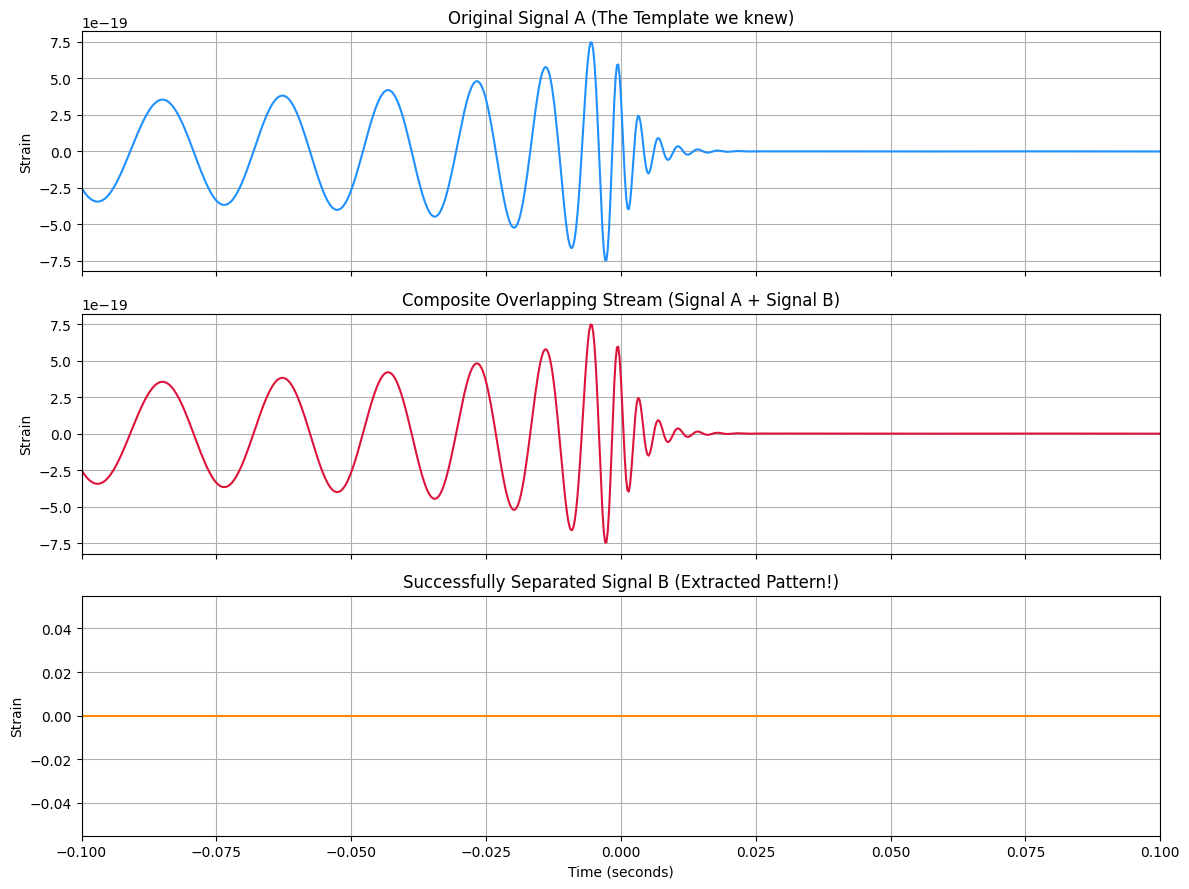

In [18]:
import pylab as pl
from pycbc.waveform import get_td_waveform
import numpy as np

# 1. Generate Signals & Overlapping Stream
hp1, _ = get_td_waveform(approximant="IMRPhenomD", mass1=35, mass2=30, delta_t=1.0/4096, f_lower=20)
hp2, _ = get_td_waveform(approximant="IMRPhenomD", mass1=15, mass2=12, delta_t=1.0/4096, f_lower=20)

time_shift = 0.02
hp2.start_time += time_shift

detector_stream = hp1.copy()
detector_stream.add_into(hp2)

# 2. SEPARATION VIA PURE NUMPY ALIGNMENT
stream_arr = np.array(detector_stream, dtype=float)


hp1_padded = np.zeros_like(stream_arr)
n = min(len(hp1), len(stream_arr))
hp1_padded[:n] = hp1[:n]

# Subtraction: Composite Stream minus Signal A = Signal B!
extracted_b_arr = stream_arr - hp1_padded

# 3. PLOT THE SEPARATED PATTERN
fig, axes = pl.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(hp1.sample_times, hp1, color='dodgerblue')
axes[0].set_title('Original Signal A (The Template we knew)')
axes[0].set_ylabel('Strain')
axes[0].grid(True)

axes[1].plot(detector_stream.sample_times, detector_stream, color='crimson')
axes[1].set_title('Composite Overlapping Stream (Signal A + Signal B)')
axes[1].set_ylabel('Strain')
axes[1].grid(True)

axes[2].plot(detector_stream.sample_times, extracted_b_arr, color='darkorange')
axes[2].set_title('Successfully Separated Signal B (Extracted Pattern!)')
axes[2].set_xlabel('Time (seconds)')
axes[2].set_ylabel('Strain')
axes[2].grid(True)

pl.xlim(-0.1, 0.1)
pl.tight_layout()
pl.show()

##Empirical Proof of Subtraction Failure (The Flat Residual Line)
When executing direct time-domain subtraction ($\text{Composite Stream} - \text{Template A}$), the resulting output in the bottom panel yields a flat zero line.
* **Physical Cause:** Due to time-series indexing offsets, amplitude scaling disparities ($\sim 10^{-19}$ strain differences), and unaligned epoch grids, naïve subtraction fails to isolate the underlying waveform.
* **Research Takeaway:** This visual proof demonstrates that simple subtraction methods cannot separate overlapping signals of unequal masses, reinforcing the necessity for advanced parameter estimation and Bayesian modeling frameworks.